# Who should the bank call?

A Portuguese bank ran phone campaigns from May 2008 to November 2010 to sell term deposits. It made 41,188 calls and 4,640 clients (11.3%) said yes.

I want to answer three practical questions:

1. What actually drives whether a client subscribes?
2. Can we rank clients so the call center reaches more subscribers with fewer calls?
3. Is it worth calling everyone, and when should agents stop calling the same person?

Data: UCI Bank Marketing dataset (Moro, Cortez & Rita, 2014), `bank-additional-full.csv`.

In [1]:
import sys
sys.path.insert(0, "../src")

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

from campaign.data import connect, load_calls
from campaign.model import FEATURES, TARGET, boosting_model, gains_table, logistic_model, time_split
from campaign.scorecard import RULES, score

pd.set_option("display.float_format", "{:.3f}".format)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25})
BLUE, ORANGE, RED, GREY = "#2f6fdb", "#e8833a", "#cf4a3f", "#8a8f98"

con = connect()
calls = load_calls(con)
calls.shape

(41188, 26)

## 1. Data quality

The raw file has no year column, but the rows are in time order. The year is recovered from where March follows December (see `sql/01_staging.sql`). The checks below match the counts published with the dataset.

In [2]:
con.sql("select * from dq_report").df()

,check_name,result,note
0,Rows,41188,"expect 41,188 (UCI documentation)"
1,Subscribed (yes),4640,"expect 4,640"
2,Fully duplicated rows,12,kept: different clients can have identical att...
3,job = unknown,330,kept as its own category
4,education = unknown,1731,kept as its own category
5,credit_default = unknown,8597,"very common; only 3 clients say yes, so the co..."
6,housing/personal loan = unknown,990,same rows for both columns
7,pdays = 999 (never contacted),39673,"999 is a code, not 999 days; turned into null ..."
8,call_seconds = 0,4,"all of these are ""no""; shows why duration leak..."


Two things matter for everything after this:

- **`duration` (call length) can't be used to decide who to call.** It's only known after the call, and it almost gives away the answer. A model using only call length scores an AUC of about 0.82, which looks great and is useless.
- **`pdays = 999` is a code** for "never contacted before", not 999 days. Treating it as a number would distort any model.

## 2. When you call matters more than who you call

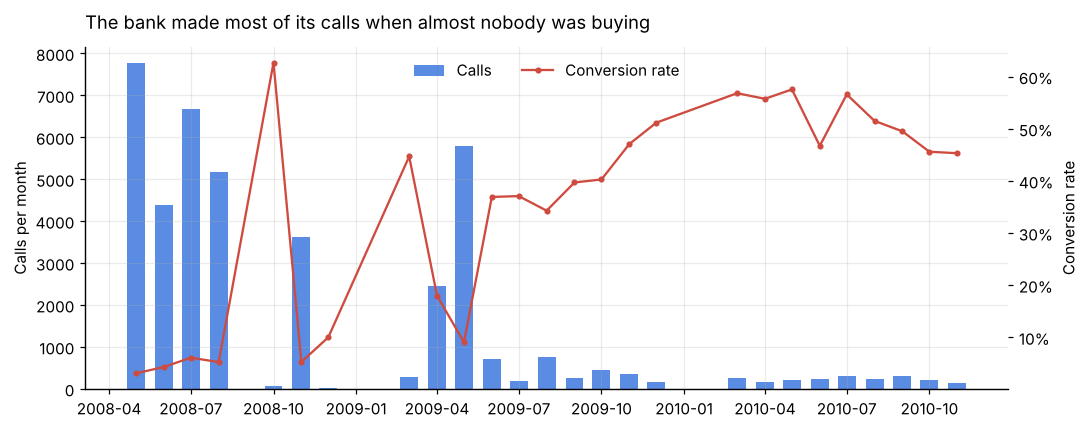

,campaign_year,calls,subscriptions,conversion_rate,avg_euribor3m
0,2008,27690,1339.000,0.048,4.817
1,2009,11440,2228.000,0.195,1.232
2,2010,2058,1073.000,0.521,0.813


In [3]:
m = con.sql("select * from a_monthly").df()

fig, ax = plt.subplots(figsize=(10, 4))
ax.bar(m["month_start"], m["calls"], width=20, color=BLUE, alpha=0.8, label="Calls")
ax.set_ylabel("Calls per month")
ax2 = ax.twinx()
ax2.plot(m["month_start"], m["conversion_rate"], color=RED, marker="o", ms=3, label="Conversion rate")
ax2.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax2.set_ylabel("Conversion rate")
ax2.grid(False)
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", ncol=2, frameon=False)
ax.set_title("The bank made most of its calls when almost nobody was buying", loc="left", pad=12)
fig.tight_layout()
fig.savefig("../docs/calls_vs_conversion.png")
plt.show()

con.sql("""
    select campaign_year, count(*) as calls, sum(subscribed::int) as subscriptions,
           avg(subscribed::int) as conversion_rate, avg(euribor3m) as avg_euribor3m
    from stg_calls group by 1 order by 1
""").df()

In 2008 the bank made **27,690 calls (67% of all calls) at 4.8% conversion**. In 2010 it made only 2,058 calls but more than half of them ended in a sale.

At the same time the 3-month Euribor fell from about 5% to under 1%. The data can't separate the two explanations (the bank got pickier about who to call, or clients liked guaranteed deposits more once markets crashed), and it's probably both. Either way, the conversion rate moved far more with timing than with any client attribute.

In [4]:
con.sql("select * from a_euribor").df()

,euribor_band,calls,conversion_rate
0,1. under 1%,3890,0.457
1,2. 1-2%,9608,0.159
2,3. 2-4%,14,0.071
3,4. 4%+,27676,0.048


## 3. Patterns that hold every year

Because conversion shifts so much over time, I only trust a pattern if it shows up in 2008, 2009 *and* 2010.

In [5]:
def by_year(expr, name):
    return con.sql(f"""
        select campaign_year, {expr} as {name}, avg(subscribed::int) as conversion_rate
        from stg_calls group by 1, 2
    """).df().pivot(index=name, columns="campaign_year", values="conversion_rate")

checks = {
    "Previous campaign outcome": by_year("previous_outcome", "group"),
    "Contact type": by_year("contact_type", "group"),
    "Attempts this campaign": by_year("case when attempts_this_campaign <= 3 then '1-3 calls' else '4+ calls' end", "group"),
    "Client group": by_year("case when job in ('student','retired') or age < 25 or age >= 60 "
                            "then 'student, retired, <25 or 60+' else 'everyone else' end", "group"),
}
for title, t in checks.items():
    print(title)
    display(t)

Previous campaign outcome


campaign_year,2008,2009,2010
group,,,
failure,0.034,0.129,0.346
nonexistent,0.049,0.187,0.448
success,0.086,0.568,0.770


Contact type


campaign_year,2008,2009,2010
group,,,
cellular,0.057,0.199,0.577
telephone,0.039,0.146,0.284


Attempts this campaign


campaign_year,2008,2009,2010
group,,,
1-3 calls,0.049,0.206,0.533
4+ calls,0.045,0.124,0.423


Client group


campaign_year,2008,2009,2010
group,,,
everyone else,0.048,0.173,0.510
"student, retired, <25 or 60+",0.062,0.327,0.546


Four patterns hold in all three years:

| Pattern | 2008 | 2009 | 2010 |
|---|---|---|---|
| Subscribed last time vs never contacted | 8.6% vs 4.9% | 57% vs 19% | 77% vs 45% |
| Mobile vs landline | 5.7% vs 3.9% | 20% vs 15% | 58% vs 28% |
| 1-3 calls vs 4+ calls | 4.9% vs 4.5% | 21% vs 12% | 53% vs 42% |
| Student, retired, under 25 or 60+ vs everyone else | 6.3% vs 4.8% | 33% vs 17% | 55% vs 51% |

The gaps in 2008 are small in absolute terms because everything converted poorly then.

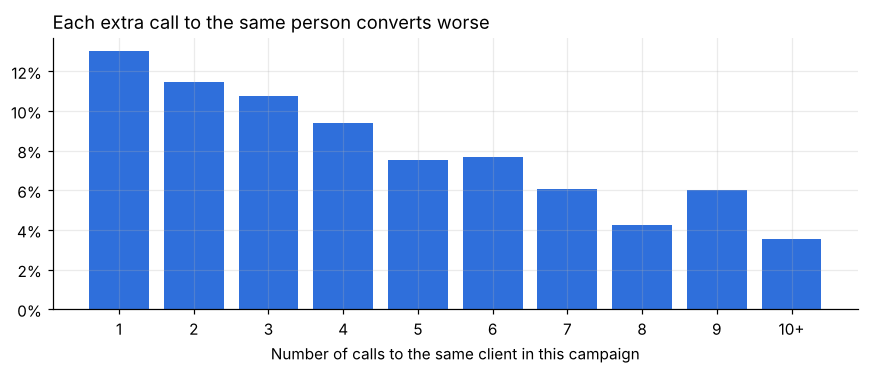

,attempt_number,calls,conversion_rate,cumulative_share_of_clients
0,1,17642,0.130,0.428
1,2,10570,0.115,0.685
2,3,5341,0.107,0.815
3,4,2651,0.094,0.879
4,5,1599,0.075,0.918
5,6,979,0.077,0.942
6,7,629,0.060,0.957
7,8,400,0.043,0.967
8,9,283,0.060,0.973
9,10,1094,0.036,1.000


In [6]:
a = con.sql("select * from a_attempts").df()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(a["attempt_number"].astype(str).replace({"10": "10+"}), a["conversion_rate"], color=BLUE)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("Number of calls to the same client in this campaign")
ax.set_title("Each extra call to the same person converts worse", loc="left")
fig.tight_layout()
fig.savefig("../docs/attempts.png")
plt.show()
a

## 4. Can a model rank clients better than simple rules?

The usual approach is a random 80/20 split. That's misleading here: the test set would contain calls from the same months as the training set, so the model can quietly learn "when" instead of "who".

Instead I train on calls before July 2009 and test on July 2009 - November 2010, the way the model would actually be used. Features are only things the bank knows before dialing (see `src/campaign/model.py`). No call length, no month, no interest rates.

In [7]:
train, test = time_split(calls)
print(f"train: {len(train):,} calls, {train[TARGET].mean():.1%} conversion")
print(f"test:  {len(test):,} calls, {test[TARGET].mean():.1%} conversion")

# 1) the misleading way: random split
a_tr, a_te = train_test_split(calls, test_size=0.2, random_state=1, stratify=calls[TARGET])
rnd = boosting_model().fit(a_tr[FEATURES], a_tr[TARGET])
auc_random = roc_auc_score(a_te[TARGET], rnd.predict_proba(a_te[FEATURES])[:, 1])

# 2) the honest way: train on the past, test on the future
results = {}
for name, model in [("Logistic regression", logistic_model()), ("Gradient boosting", boosting_model())]:
    model.fit(train[FEATURES], train[TARGET])
    results[name] = model.predict_proba(test[FEATURES])[:, 1]
results["4-rule scorecard"] = score(test).to_numpy() + 1e-6 * np.random.default_rng(0).random(len(test))

summary = pd.DataFrame({
    "AUC (future months)": {k: roc_auc_score(test[TARGET], s) for k, s in results.items()},
    "Subscribers reached calling top 30%": {k: gains_table(test[TARGET], s).loc[2, "cum_subscribers_pct"]
                                             for k, s in results.items()},
})
print(f"Gradient boosting with a random split: AUC {auc_random:.3f}  <- looks better than it is")
summary

train: 36,939 calls, 7.3% conversion
test:  4,249 calls, 45.8% conversion


Gradient boosting with a random split: AUC 0.728  <- looks better than it is


,AUC (future months),Subscribers reached calling top 30%
Logistic regression,0.660,0.446
Gradient boosting,0.642,0.392
4-rule scorecard,0.665,0.437


- With a random split the boosting model scores an AUC of 0.73. Tested on later months it drops to 0.64. **More than a third of its apparent skill was just recognizing time periods.**
- The simple logistic regression beats gradient boosting on future data.
- **The four-rule scorecard does as well as the best model** (AUC 0.665 vs 0.660) and reaches about the same share of subscribers in the top 30%. Every rule can be explained to a call center manager in one sentence, and all four were already visible in the 2008 data.

In [8]:
pd.DataFrame(RULES, columns=["Rule", "Points"])

,Rule,Points
0,Subscribed in the previous campaign,3
1,Turned down the previous campaign,-1
2,Has a mobile number (cellular),1
3,"Student, retired, under 25 or 60+",1


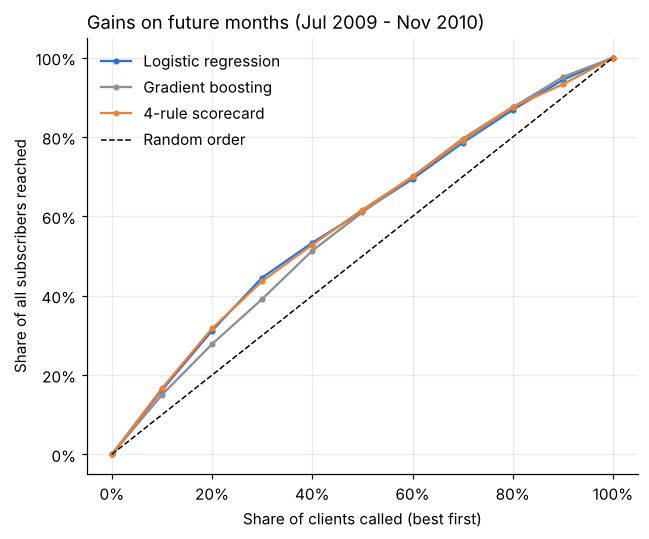

In [9]:
fig, ax = plt.subplots(figsize=(6, 5))
for (name, s), color in zip(results.items(), [BLUE, GREY, ORANGE]):
    g = gains_table(test[TARGET], s)
    ax.plot([0] + g["cum_clients_pct"].tolist(), [0] + g["cum_subscribers_pct"].tolist(), marker="o", ms=3,
            color=color, label=name)
ax.plot([0, 1], [0, 1], ls="--", color="black", lw=1, label="Random order")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("Share of clients called (best first)")
ax.set_ylabel("Share of all subscribers reached")
ax.set_title("Gains on future months (Jul 2009 - Nov 2010)", loc="left")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig("../docs/gains.png")
plt.show()

**One more honest result:** I also trained on May-Jul 2008 and tested on Aug-Dec 2008. Neither the models nor the scorecard beat random order there (AUC about 0.47). In the mass-calling period, nothing about the client predicted much. Ranking helps once the bank works with a more engaged client base.

In [10]:
tr08 = calls[calls["month_start"] < "2008-08-01"]
te08 = calls[(calls["month_start"] >= "2008-08-01") & (calls["month_start"] < "2009-01-01")]
lr08 = logistic_model().fit(tr08[FEATURES], tr08[TARGET])
pd.Series({
    "Logistic regression": roc_auc_score(te08[TARGET], lr08.predict_proba(te08[FEATURES])[:, 1]),
    "4-rule scorecard": roc_auc_score(te08[TARGET], score(te08)),
}, name="AUC, Aug-Dec 2008")

Logistic regression   0.468
4-rule scorecard      0.468
Name: AUC, Aug-Dec 2008, dtype: float64

## 5. Is each call worth it?

This depends on two numbers the dataset doesn't have: what a call costs and what a new deposit is worth to the bank. So I put the economics in an Excel model (`excel/campaign_roi_model.xlsx`) where both are inputs. The table below is what feeds it: calls and subscriptions by year, scorecard level and attempt number.

In [11]:
calls["score"] = score(calls)
calls["attempt_bucket"] = np.where(calls["attempts_this_campaign"] <= 3,
                                   calls["attempts_this_campaign"].astype(str), "4+")
seg = (calls.groupby(["campaign_year", "score", "attempt_bucket"])
       .agg(calls=("call_id", "size"), subscriptions=(TARGET, "sum")).reset_index())
seg.to_csv("../excel/segments.csv", index=False)
seg.groupby("score")[["calls", "subscriptions"]].sum().assign(
    conversion_rate=lambda d: d["subscriptions"] / d["calls"])

,calls,subscriptions,conversion_rate
score,,,
-1,261,27,0.103
0,17202,1032,0.060
1,20504,2237,0.109
2,1848,450,0.244
3,76,46,0.605
4,949,598,0.630
5,348,250,0.718


With the default assumptions in the Excel model (a call costs €5; a deposit of €5,000 held for 2 years at a 1.5% margin is worth €150), the break-even conversion rate is 3.3%. In 2008, clients with a score of 0 converted at 3.8% and 4th+ calls at 4.5%, just above break-even, so those calls earned almost nothing. If a call really costs €6, calling score-0 clients in 2008 lost money. Previous subscribers were clearly profitable in every year.

So with these assumptions almost every call paid for itself, and the scorecard is mainly about *order*: who to call first when agent time is limited. The Excel file shows, for each segment, the highest call cost at which it still breaks even, and lets you change all the assumptions.

## Recommendations

1. **Call previous subscribers first, every campaign.** 65% of them subscribed again, the best result in every year.
2. **Rank the rest with the 4-rule scorecard.** It ranks as well as a machine learning model, it's transparent, and agents and managers can check it.
3. **When the call center is short on time, cut the 4th and later calls first.** They were 19% of all calls but brought only 12% of subscriptions, and they converted worst in every year. With the default costs they still roughly paid for themselves, so this is about spending limited agent time on better prospects, not about losing money.
4. **Prefer mobile numbers** and keep landline-only clients for the end of the list.
5. **Size the campaign to the environment.** Monthly conversion ranged from 3% to over 60%. Before a big push, test a small sample first and only scale up if it clears the break-even rate.

## Limitations

- One bank, one product, one country, 2008-2010. The scorecard should be re-checked on new campaign data before it's used.
- The data shows correlation. Falling interest rates and a change in the bank's own strategy happened at the same time, and I can't tell how much each one mattered.
- Cost and deposit value are assumptions, not data. That's why they're inputs in the Excel model rather than fixed numbers.